# 07 · Designing a rescue with a safety gate

**Place in the argument.** Track 2. It turns a therapeutic idea into an auditable chain: what
must be true, what evidence exists, and which measurement can kill the hypothesis.

**Main output.** A matrix of eight bridges × ten evidence dimensions, a three-arm experimental
portfolio, and the design of the next experiment. It is not clinical efficacy, a recommendation
or a proof of safety.

> An **experimental portfolio** is nominated: two pharmacological hypotheses (azithromycin,
> arimoclomol) and an adversarial comparator (sirolimus), for **preclinical discrimination**.
> **No therapeutic winner is nominated and no compound is recommended for administration.**
>
> An earlier version of this header said "NO DRUG NOMINATION", and the notebook then nominated
> three arms. Each sentence could pass as prudent on its own; together they were a contradiction.
>
> Every piece of evidence cited has an identifier **verified within the project**. Where evidence
> is missing the cell says *gap*, not a plausible citation.

## The question

**Is there a plausible, falsifiable and safe therapeutic mechanism for this patient?**

## The correction that reorganises everything

Grouping the evidence under "proteostasis" put two interventions with different therapeutic
logic, and **potentially opposite oncological consequences**, in the same box:

| | T2-A · upstream | T2-B · downstream |
|---|---|---|
| Chain | The variant would destabilise BUBR1; raising its abundance would improve the checkpoint | The already aneuploid cell is stressed; raising HSPs would help it tolerate that |
| Intended effect | **fewer** new aneuploid cells | the existing ones **survive better** |
| Risk | could reduce chromosomal instability (CIN) | could increase the survival of unstable cells |

In a child who has already had a rhabdomyosarcoma, **that difference is everything**.

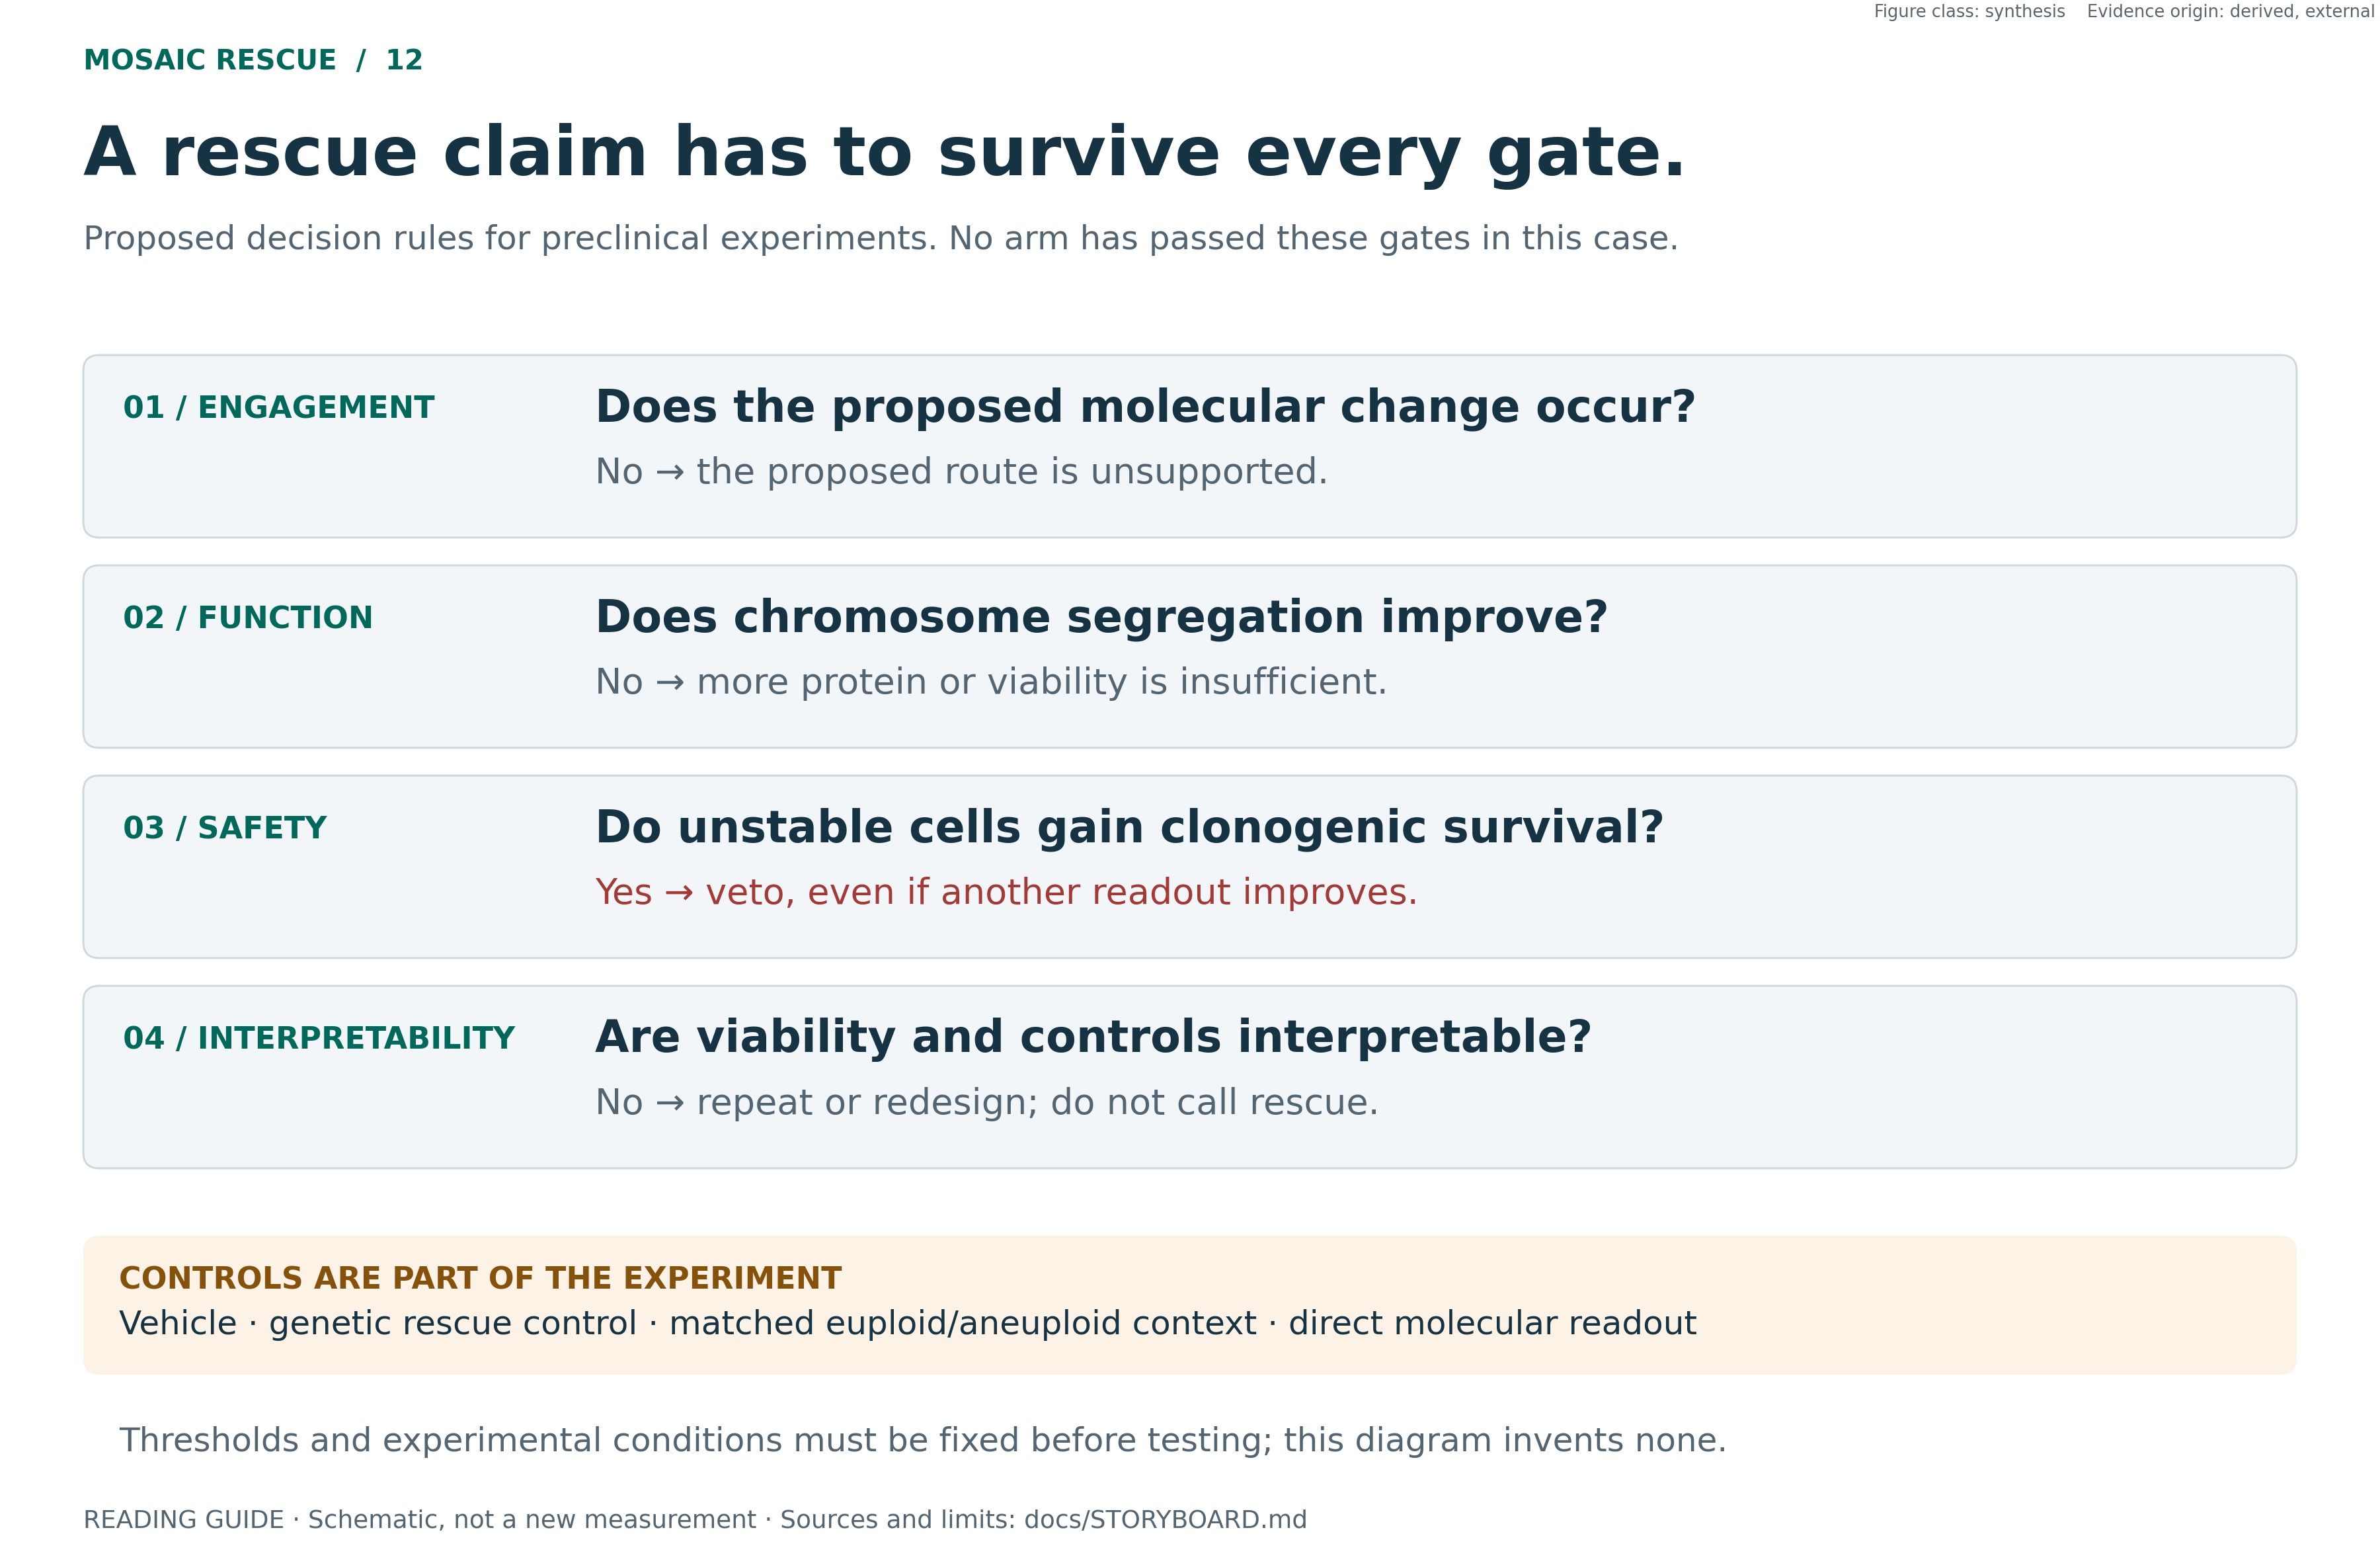

**`SYNTHESIS` · DERIVED / EXTERNAL.** Proposed rules to veto an apparent rescue that favours unstable cells; they are not experimental results yet. Reviewed figure, embedded without re-running the original analysis · [sources and limits](../docs/STORYBOARD.md) · [figure QA](../PUBLICATION_FIGURE_QA.md)

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # the pipeline uses paths relative to the repo root
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # inline figures + provenance captions
print("environment ready · figures in this notebook render inline, each with a provenance caption")

environment ready · figures in this notebook render inline, each with a provenance caption


In [2]:
fl.labels("Inventory", "What a gap does not mean")

## Primary result 1 · the evidence matrix

A box-and-arrow map explains **the idea**. It does not show **what evidence exists**. This matrix
crosses the eight bridges with ten evidence dimensions and says, cell by cell, what is there.

It is read from **`research/track2_evidence.tsv`**, a versioned file: each cell is a row with its
source. **Not a single box is written inside the figure code**: a box cannot be audited or
compared across versions; a row can.

Hard rule of the file: **no cell other than `ABSENT` may lack a source**, and the notebook checks
it before drawing.

In [3]:
TSV = "research/track2_evidence.tsv"
raw = [l.rstrip(chr(10)).split(chr(9)) for l in io.open(TSV, encoding="utf-8")
       if not l.startswith("#") and l.strip()]
HDR, EV = raw[0], [dict(zip(raw[0], r + [""] * (len(raw[0]) - len(r)))) for r in raw[1:]]

# Column and dimension keys are stored in the versioned file as written; they are data keys.
DIMS = ["paciente", "mva_humana", "celulas_aneuploides", "otro_contexto",
        "perturbacion_genetica", "perturbacion_farmacologica",
        "abundancia_bubr1", "proteostasis", "cin", "supervivencia_clonogenica"]
BR = sorted({int(e["puente"]) for e in EV})
CELL = {(int(e["puente"]), e["dimension"]): e for e in EV}

# The hard rule, checked here and not only written in the file
orphans = [e for e in EV if e["clase"] != "ABSENT" and not e["fuente"].strip()]
assert not orphans, f"cells without a source: {[(e['puente'], e['dimension']) for e in orphans]}"
assert len(EV) == len(BR) * len(DIMS), f"the matrix is incomplete: {len(EV)} rows"

import collections as _c
cnt = _c.Counter(e["clase"] for e in EV)
print(f"  {TSV}  ·  {len(EV)} cells = {len(BR)} bridges x {len(DIMS)} dimensions")
print(f"  every cell other than ABSENT carries a source: OK")
print()
for k in ("DIRECT", "GENETIC", "NEAR", "CONTRADICTORY", "ABSENT"):
    print(f"    {k:<16}{cnt.get(k,0):>4}  ({100*cnt.get(k,0)/len(EV):.0f} %)")
print()
sources = sorted({e["fuente"] for e in EV if e["fuente"].strip()})
from src.figures.fig07_evidence import publications as _pubs
_p, _i = _pubs(sources)
print(f"  distinct publications cited: {len(_p)}  ·  internal artefacts: {len(_i)}")
print(f"  (distinct text strings: {len(sources)}; an article cited with and without its DOI")
print(f"   is ONE publication, and counting it twice inflated the denominator)")
for f in sources:
    print(f"    {f}")

  research/track2_evidence.tsv  ·  80 cells = 8 bridges x 10 dimensions
  every cell other than ABSENT carries a source: OK

    DIRECT             9  (11 %)
    GENETIC            2  (2 %)
    NEAR               5  (6 %)
    CONTRADICTORY      3  (4 %)
    ABSENT            61  (76 %)

  distinct publications cited: 4  ·  internal artefacts: 2
  (distinct text strings: 7; an article cited with and without its DOI
   is ONE publication, and counting it twice inflated the denominator)
    DOI 10.1007/s00439-008-0572-y
    DOI 10.1038/s41467-025-60857-4
    PMID 20516114
    PMID 34481829
    PMID 34481829 · DOI 10.1016/j.jlr.2021.100114
    docs/EVIDENCE.md
    src/structure/ (EXP-010, EXP-011)


### Main figure 1 · eight bridges × ten evidence dimensions

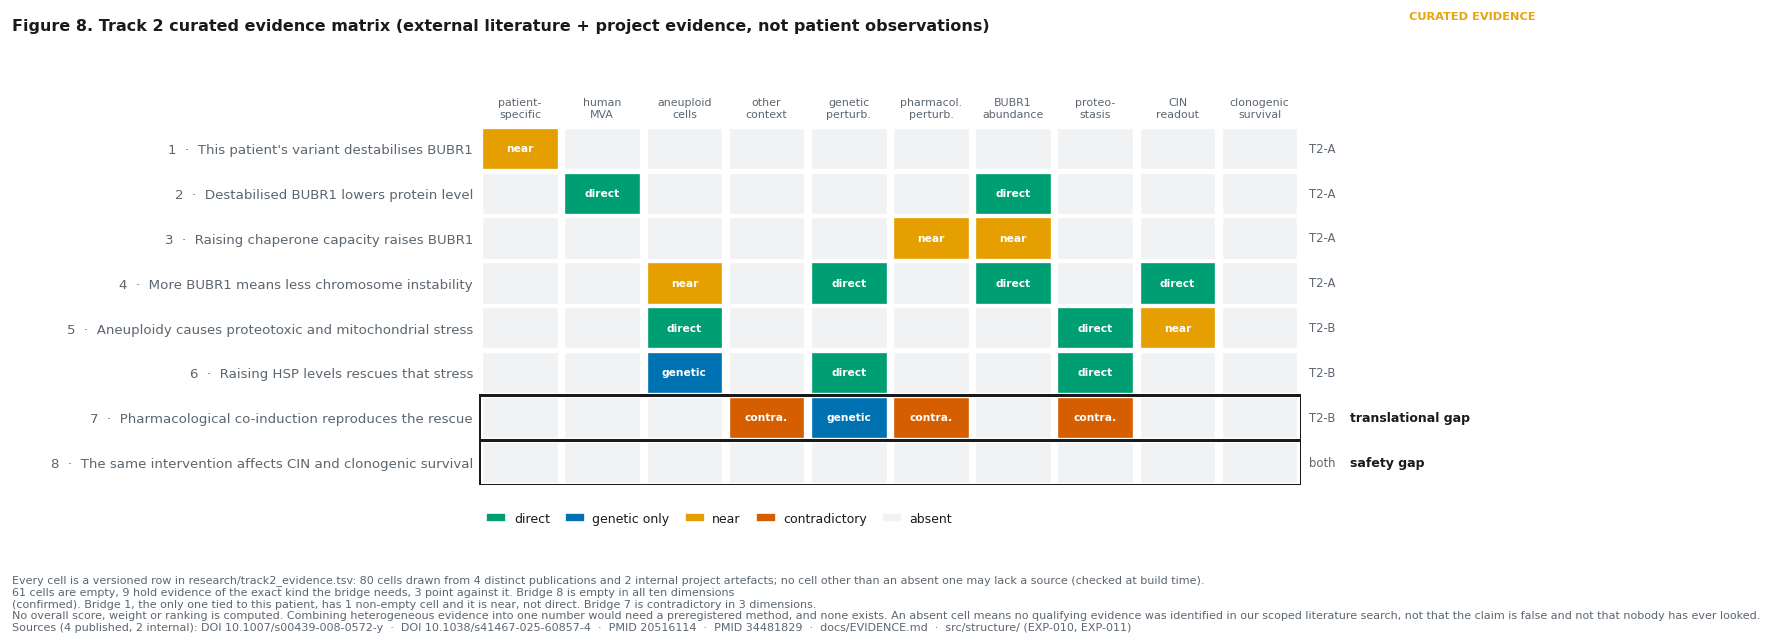

> **Main figure 1 · Track 2 curated evidence matrix**  
> `EXP-016 · EXP-016b` · figure class `CURATED_EVIDENCE`, scientific figure · evidence origin `EXTERNAL`  
> *Inventory.* what evidence really exists for each bridge. Of the 80 cells, 61 are empty, 9 hold evidence of exactly the type the bridge needs and 3 point AGAINST it, over 4 distinct publications plus 2 internal artefacts. Row 8 is empty in all ten dimensions: that is the safety gap. Row 1, the only one that connects to this patient, has a single non-empty cell, and it is NEAR, not DIRECT. Bridge 7 is the TRANSLATIONAL gap.  
> **What a gap does not mean.** that Track 2 is valid or invalid. It is an inventory of curated evidence (external literature plus project evidence), not experimental observations of the patient, which is why it is not labelled simply DATA. An ABSENT cell says that OUR bounded search found no qualifying evidence, not that the claim is false or that nobody has ever looked. And NO global score is computed: combining heterogeneous evidence into one number would need a preregistered method that does not exist.  
> data: `research/track2_evidence.tsv · 80 versioned cells, each with a source` · library: `matplotlib` · provenance: `figures/pub/fig07_track2_evidence_matrix.svg + .png 300 dpi`

In [4]:
from src.figures import fig07_evidence as FE

fig, _st = FE.build(EV)
_n_abs = _st["counts"].get("ABSENT", 0)
_n_dir = _st["counts"].get("DIRECT", 0)
_n_con = _st["counts"].get("CONTRADICTORY", 0)
fl.pub(fig, "Main figure 1 · Track 2 curated evidence matrix",
       "EXP-016 · EXP-016b", "EXTERNAL", "CURATED_EVIDENCE",
       f"what evidence really exists for each bridge. Of the {len(EV)} cells, {_n_abs} are "
       f"empty, {_n_dir} hold evidence of exactly the type the bridge needs and {_n_con} point "
       f"AGAINST it, over {len(_pubs(_st['sources'])[0])} distinct publications plus "
       f"{len(_pubs(_st['sources'])[1])} internal artefacts. Row 8 is empty in all ten "
       f"dimensions: that is the safety gap. Row 1, the only one that connects to this patient, "
       f"has a single non-empty cell, and it is NEAR, not DIRECT. Bridge 7 is the TRANSLATIONAL "
       f"gap.",
       "that Track 2 is valid or invalid. It is an inventory of curated evidence (external "
       "literature plus project evidence), not experimental observations of the patient, which "
       "is why it is not labelled simply DATA. An ABSENT cell says that OUR bounded search found "
       "no qualifying evidence, not that the claim is false or that nobody has ever looked. And "
       "NO global score is computed: combining heterogeneous evidence into one number would need "
       "a preregistered method that does not exist.",
       source="research/track2_evidence.tsv · 80 versioned cells, each with a source",
       lib="matplotlib", slug="fig07_track2_evidence_matrix")

## Primary result 2 · the eight bridges, as a chain

Every claim declares **which bridge it supports**. Evidence for one bridge **does not count** for
another.

| # | Bridge | Route | Status | What exists |
|---|---|---|---|---|
| 1 | *this patient's* variant → BUBR1 instability | T2-A | **gap** | structural inference and conservation only |
| 2 | instability → less protein | T2-A | supported | low levels in patients, including with missense, but from other alleles |
| 3 | raising chaperones → RAISES BUBR1 | T2-A | **gap** | unresolved: basal dependence shown, the gain unmeasured |
| 4 | more BUBR1 → less CIN | T2-A | supported | a gradient of 8.5 to 77 %; clear aneuploidy below ~50 % ([DOI](https://doi.org/10.1007/s00439-008-0572-y)) |
| 5 | aneuploidy → proteotoxic stress | T2-B | supported | p62 with mitochondrial precursors, low mtDNA ([DOI](https://doi.org/10.1038/s41467-025-60857-4)) |
| 6 | raising HSPs (GENETIC) → rescue | T2-B | partial | rescues, BUT the effect depended on karyotype: one line did not respond |
| 7 | PHARMACOLOGICAL co-induction → the same rescue | T2-B | **against** | no direct evidence; a verified counterexample ([PMID 34481829](https://pubmed.ncbi.nlm.nih.gov/34481829/)) |
| 8 | the intervention → effect on CIN and clonogenic survival | both | **empty** | NO qualifying evidence in either direction |

No broken bridge has been closed as negative: they are **unresolved**, which is different.

## Primary result 3 · bridge 7, the falsifiable core

A bounded search with a classification fixed in advance:

| Class | Found |
|---|---|
| `DIRECT`: aneuploid cells, co-inducer and rescue | None |
| `NEAR`: co-induction in another proteotoxic context | Yes, but **not admitted as a substitute** |
| `GENETIC`: overexpression only | Yes, and it is all the evidence for bridge 6 |
| **CONTRADICTORY** | **Two, verified** |

**The counterexample ([PMID 34481829](https://pubmed.ncbi.nlm.nih.gov/34481829/)).** In NPC1
fibroblasts, HSP70 overexpression reduced cholesterol storage; the co-inducer **did not reproduce
it** up to 500 µM, and the detail that weighs most: **it did not even induce HSP70**.

**The tension ([PMID 25205676](https://pubmed.ncbi.nlm.nih.gov/25205676/)).** In human aneuploid
cells, induction of the heat-shock response runs at **50 to 60 %** of control. What rescued was
**constitutively active HSF1**.

> **Frozen wording:**
>
> *HSF1 impairment makes the pathway both mechanistically relevant and pharmacologically
> uncertain. Genetic augmentation can bypass the deficit; whether a stress-dependent
> pharmacological co-inducer can amplify the impaired endogenous response sufficiently
> remains unresolved.*

## Robustness · "try to kill it"

**The efficacy signal and the oncological-risk signal are the same measurement.**

If an intervention preferentially rescues the **most** aneuploid cells, that is at once the proof
that the mechanism is the proposed one **and** the proof that the clonogenic survival of
genomically unstable cells is being improved. That is why the assay reads chromosome
segregation and clonogenic survival together, and why more survival of unstable cells is a
**veto**, not a win.

## Contradicting evidence, declared

| Claim | Counter-evidence |
|---|---|
| Raising HSPs is therapeutic | A co-inducer **was not effective** in ALS |
| Genetic ≈ pharmacological | **PMID 34481829**: the genetic route rescued, the pharmacological one did not, and did not induce HSP70 |
| Genetic rescue is universal | It depended on **karyotype**; one aneuploid line did not respond |
| Helping the aneuploid cell is good | **It is the oncological definition of an early step of tumorigenesis** |

## Primary result 4 · the experimental portfolio, not a winner

So far the notebook has said what evidence is **missing**. This section says what would be
**done with that**, which is what the official Track 2 deliverable asks for: to propose approved
drug or drugs supported by the mechanism.

The honest answer is not a name. It is a **three-arm portfolio with three different roles**, plus
three controls, formalised in `research/track2_candidates.tsv` and validated by `src/verify.py`.
It carries no global score, ranking or winner, for the same reason the bridge matrix does not:
combining heterogeneous evidence into one number needs a preregistered method that does not
exist.

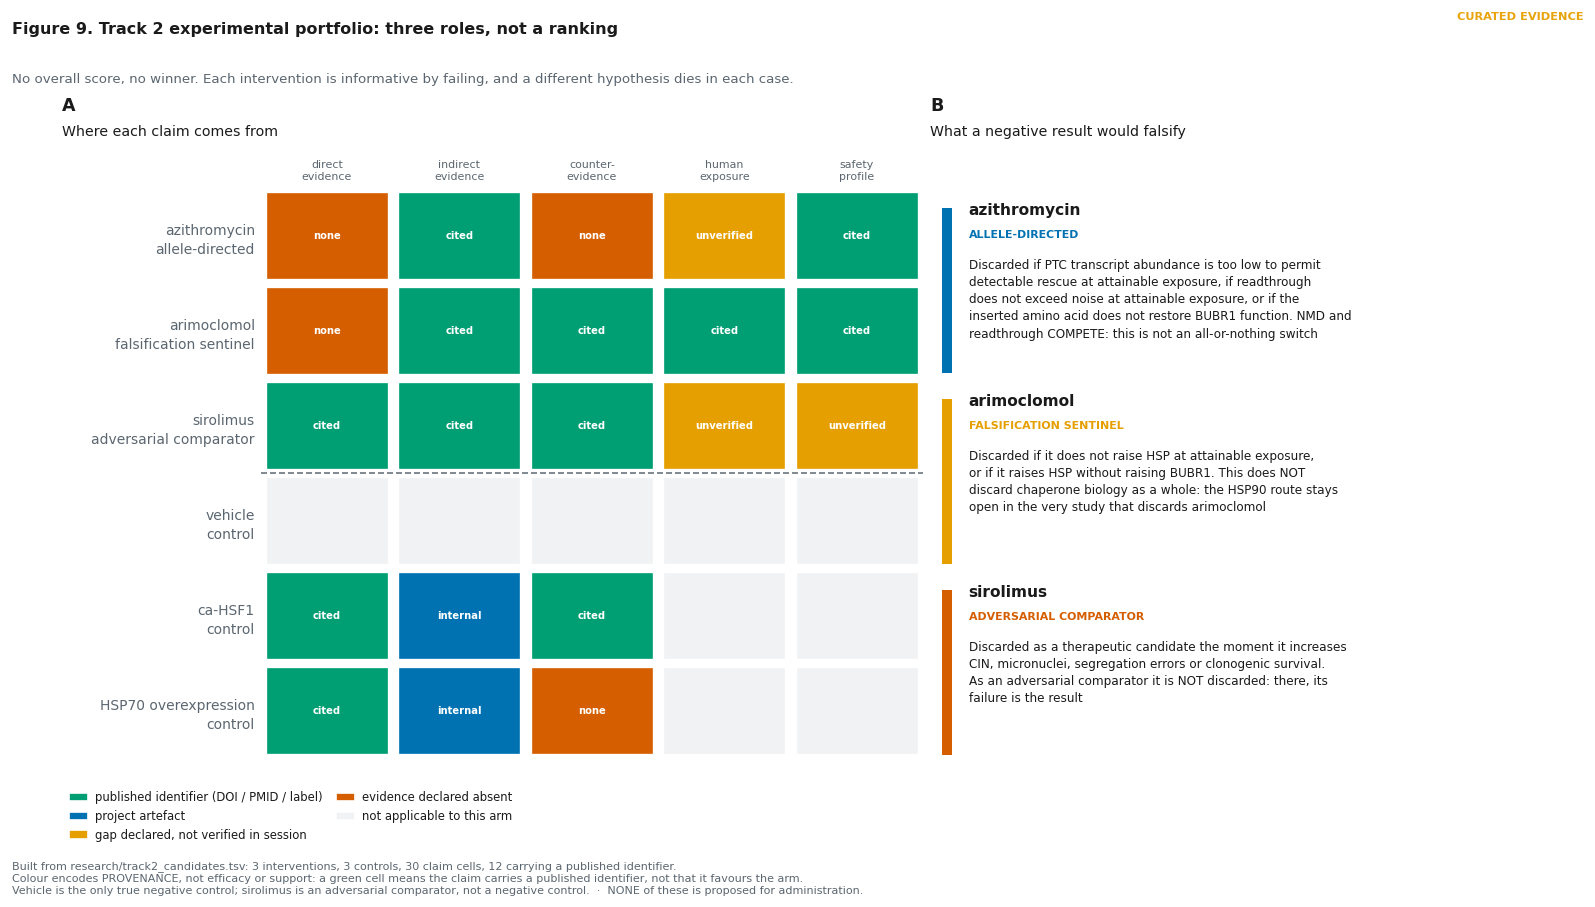

> **Main figure 2 · Track 2 experimental portfolio**  
> `EXP-016 · EXP-016b` · figure class `CURATED_EVIDENCE`, scientific figure · evidence origin `EXTERNAL`  
> *Inventory.* the three arms do not compete for first place: they fill different roles and each is informative WHEN IT FAILS. Of the 30 claim cells, 12 carry a published identifier and the rest are DECLARED absences or gaps. Azithromycin is the only arm aimed at THIS patient's truncating allele and has no direct evidence. Arimoclomol is the only one with verified counter-evidence, which is why it serves as a sentinel. Sirolimus is the only one with direct pharmacological evidence, and that evidence is PARTLY NEGATIVE on the outcome that matters.  
> **What a gap does not mean.** that none of the three works, or that any of them should be given. It is NOT a therapeutic nomination: it is the instrument to decide which would be the FIRST preclinical experiment. No candidate in this table is proposed for administration to any patient, and this project makes no clinical recommendations.  
> data: `research/track2_candidates.tsv · 6 versioned rows, each claim with an identifier or a declared gap` · library: `matplotlib` · provenance: `figures/pub/fig08_track2_portfolio.svg + .png 300 dpi`

In [5]:
from src.figures import fig08_portfolio as FP

_rows = FP.read()
fig, _pt = FP.build(_rows)
_cells = len(_rows) * len(FP.CLAIMS)
fl.pub(fig, "Main figure 2 · Track 2 experimental portfolio",
       "EXP-016 · EXP-016b", "EXTERNAL", "CURATED_EVIDENCE",
       f"the three arms do not compete for first place: they fill different roles and each is "
       f"informative WHEN IT FAILS. Of the {_cells} claim cells, {_pt['cited']} carry a "
       f"published identifier and the rest are DECLARED absences or gaps. Azithromycin is the "
       f"only arm aimed at THIS patient's truncating allele and has no direct evidence. "
       f"Arimoclomol is the only one with verified counter-evidence, which is why it serves as a "
       f"sentinel. Sirolimus is the only one with direct pharmacological evidence, and that "
       f"evidence is PARTLY NEGATIVE on the outcome that matters.",
       "that none of the three works, or that any of them should be given. It is NOT a "
       "therapeutic nomination: it is the instrument to decide which would be the FIRST "
       "preclinical experiment. No candidate in this table is proposed for administration to any "
       "patient, and this project makes no clinical recommendations.",
       source="research/track2_candidates.tsv · 6 versioned rows, each claim with an "
              "identifier or a declared gap",
       lib="matplotlib", slug="fig08_track2_portfolio")

### The three roles, and why each failure teaches something different

| Arm | Role | Why it is there | What dies if it fails |
|---|---|---|---|
| **azithromycin** | `ALLELE` · allele-directed | The **only** arm that targets this patient's truncating allele, by read-through of the premature stop codon. The context pulls both ways: the stop is **UGA**, generally permissive, but carries **A at +4**, less favourable than C or U. And decisively, the **extended context** makes the response impossible to predict without measuring it ([DOI](https://doi.org/10.1038/s41467-024-46703-z)). Exposure and QT safety are known problems: it is not a clinical solution | The read-through hypothesis **for this allele**. The rest of Track 2 is untouched |
| **arimoclomol** | `SENTINEL` · falsification sentinel | The only one with **verified counter-evidence**: in NPC1 fibroblasts the genetic rescue worked and it did not, without inducing HSP70 ([PMID 34481829](https://pubmed.ncbi.nlm.nih.gov/34481829/)). It is there to **resolve bridge 7**, not to win | The pharmacological translation *arimoclomol → HSP co-induction* **in that system**. The chaperone arm does **not** fall: the HSP90 route stays open in the same study that discards it |
| **sirolimus** | `ADVERSARIAL` · safety comparator | The only one with **direct** pharmacological evidence (rapamycin at 40 µM in larvae, [DOI](https://doi.org/10.1038/s41467-026-70521-0)), and that evidence already shows the problem: it rescued the number of aneuploid neuroblasts **without** restoring Pros+ cells or brain size | Nothing, and that is the point. **As an adversarial comparator its failure is the result**: it tests the limit of the safe-rescue corridor |

And the three controls, which are not decorative:

| Control | What it separates |
|---|---|
| **vehicle** | The real zero of every readout. The **only true negative control**; no active compound is |
| **ca-HSF1** | A **contextual** positive control, in isogenic human aneuploid cells. Without it, a negative arimoclomol result is uninterpretable: one could not tell whether the drug or the biology failed. **Its rescue depended on karyotype**, and that is declared |
| **HSP70 overexpression** | A secondary mechanistic comparator. It is **not** the contextual positive control: its evidence comes from NPC1 fibroblasts, not aneuploid cells |

## Decision

| | |
|---|---|
| **Main surviving class** | Proteostasis and chaperone modulation, among the six evaluated |
| **T2-A, upstream** | `UNRESOLVED`, blocked by bridges 1 and 3 |
| **T2-B, downstream** | `UNRESOLVED`, blocked by bridges 7 and 8 |
| **Track 2 proposal** | **A portfolio of 3 interventions and 3 controls for a first preclinical experiment**, with each arm's role declared and its discard rule written in advance |
| **What IS nominated** | **Three pharmacological arms for preclinical discrimination**: two candidate hypotheses (azithromycin, arimoclomol) and an adversarial comparator (sirolimus) |
| **What is NOT nominated** | A therapeutic winner, or any clinical recommendation. None of the three meets the five conditions of the drug gate, and bridge 8 is empty for all three |
| Proteasome · clonal pruning | **Negative** |
| Stabilisation by acetylation · senolytics | **Parked** |

**The distinction behind all of the above.** Proposing an experiment is not nominating a
treatment. The drug gate requires all five: approved status · mechanistic proximity to a named
bridge · evidence **for that** bridge · a falsifiable rescue prediction · an explicit CIN/tumour
counter-test. **Today no candidate meets them**, and the portfolio exists precisely to find out
which could.

> **None of these compounds is proposed for administration to any patient.** This project
> produces a falsifiable hypothesis for preclinical research and **makes no clinical
> recommendations**.

### What this notebook does not show

That the class is the right one · that a drug that works exists · that rescuing is safe. Nor that
the therapeutic space was swept completely: **six classes chosen from the case's mechanistic
chain** were evaluated.

### Falsifier

The experiment below, with its pre-written outcomes, and the portfolio's three discard rules.
Each arm has written **in advance** which result kills it, and two of the four outcomes of the
experiment kill the hypothesis. That is what makes it falsifiable.

### Next best experiment

An isogenic aneuploid/euploid pair ± the candidate co-inducer, with a **genetic positive control**
(constitutively active HSF1) and a **mandatory readout of whether the drug induces HSPs**, because
the counterexample shows it may **not**, and without measuring it one cannot tell whether the drug
or the hypothesis failed. Measuring CIN and clonogenic survival together. This is open question 3
of the [Track 1 conclusions](../reports/TRACK1_REPORT.md), and it is only worth running once the
mechanism in this patient (phase and missense function) is confirmed.